In [3]:
'''
want to know how many streaks per image meet the 300 in one pixel brightness count
we'll use the xy coords and look at just the middle 20 pixels maybe?
although it would be convenient to do this for the training data and idk if i have xy coords for the training data...
    looks like i do!
'''

"\nwant to know how many streaks per image meet the 300 in one pixel brightness count\nwe'll use the xy coords and look at just the middle 20 pixels maybe?\nalthough it would be convenient to do this for the training data and idk if i have xy coords for the training data...\n    looks like i do!\n"

In [4]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm


import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from tensorflow import keras
import get_postage_stamps as gpsf
from scipy.ndimage import sobel

In [5]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [6]:
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")
#to get the filenames, yeah im sure there's a better way but whatever

In [7]:
np.unique(df_implants_neg["filename"])[0] #we'll start with an example

'ztf_20220820237546_000798_zr_c01_x_0003.'

In [46]:
xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"

In [47]:
xy_file = xy_path+np.unique(df_implants_neg["filename"])[0][:-5]+"1.fits"

In [48]:
image_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/images/"

In [49]:
image_file = image_path+np.unique(df_implants_neg["filename"])[0]+"_1_implanted_neg.npy"

In [12]:
with fits.open(xy_file) as hdul:
    print(hdul[1].data["x"])

[1040. 2961. 1879.  150. 1248.  434. 2802. 1383.  588. 1444. 1737.  971.
 2380. 1412. 2109.  932. 2060.  368.  737.   81.  196. 2022. 2296. 2980.
 2140.  170. 2430.  870.   97. 1714. 2411. 2883. 2853. 2867.  945.  411.]


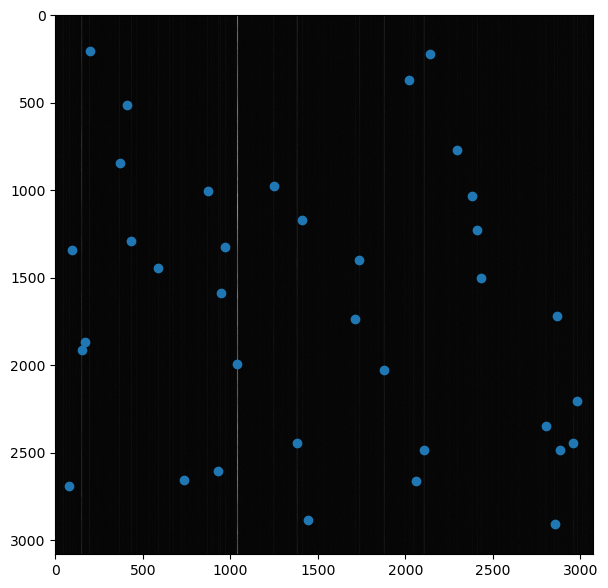

In [50]:

plt.imshow(np.sqrt(np.load(image_file)))
with fits.open(xy_file) as hdul:
    plt.scatter(hdul[1].data["x"], hdul[1].data["y"])

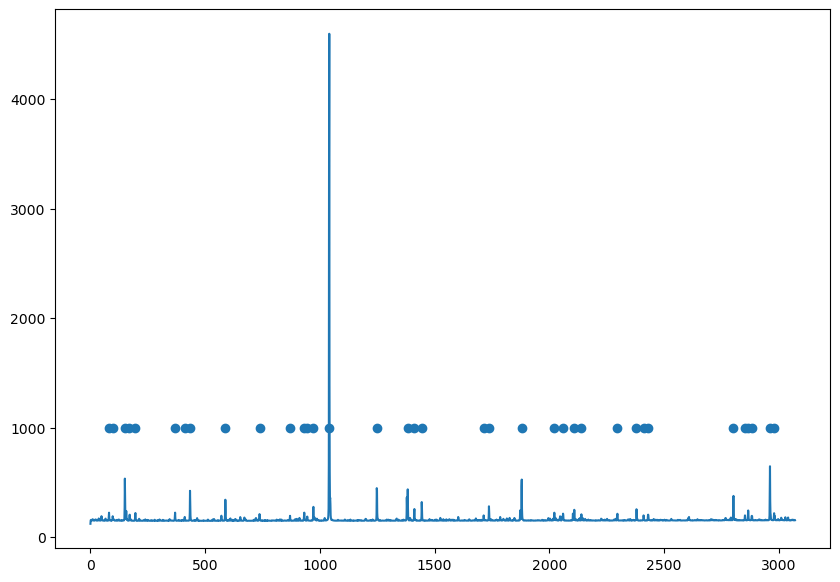

In [51]:
plt.plot(np.average(np.load(image_file), axis=0))
with fits.open(xy_file) as hdul:
    plt.scatter(hdul[1].data["x"], np.full(len(hdul[1].data["x"]), 1000))

In [25]:
image = np.load(image_file)

ValueError: Cannot load file containing pickled data when allow_pickle=False

In [16]:
#okay great so x is actually x here

#so we want to know how many streaks fulfill a 300 count brightness in the center of a 8x8 square at (xcoord, 1500) or something
bgsubtracted_image = image - rff.get_image_background(image)

In [17]:
bright_ones = []
bsize=4
    
for name in np.unique(df_implants_neg["filename"]):
    print(name)
    xy_file = xy_path+name[:-5]+"1.fits"
    # image_file = image_path+name+"_1_implanted_neg.npy"
    image_file = "/lustre/lrspec/ZTF_data/training_aug24/implant_train/"+name+"fits.fz"
    with fits.open(xy_file) as hdul:
        with fits.open(image_file) as image:
            bgsubtracted_image = image[1].data - rff.get_image_background(image[1].data)
            maxes = []
            for x in hdul[1].data["x"]: 
                if x>15 and x<3065:
                    box = bgsubtracted_image[1500-bsize:1500+bsize, int(x)-bsize:int(x)+bsize]
                    maxes.append(np.max(box))
            bright_ones.append(np.sum(np.array(maxes)>300))


ztf_20220820237546_000798_zr_c01_x_0003.
ztf_20220820237546_000798_zr_c02_x_0000.
ztf_20220820237546_000798_zr_c02_x_0001.
ztf_20220820237546_000798_zr_c02_x_0002.
ztf_20220820237546_000798_zr_c02_x_0004.
ztf_20220820237546_000798_zr_c03_x_0000.
ztf_20220820237546_000798_zr_c03_x_0003.
ztf_20220820237546_000798_zr_c03_x_0004.
ztf_20220820237546_000798_zr_c04_x_0000.
ztf_20220820237546_000798_zr_c04_x_0002.
ztf_20220820237546_000798_zr_c04_x_0003.
ztf_20220820237546_000798_zr_c04_x_0004.
ztf_20220820237546_000798_zr_c05_x_0002.
ztf_20220820237546_000798_zr_c06_x_0002.
ztf_20220820237546_000798_zr_c07_x_0000.
ztf_20220820237546_000798_zr_c07_x_0001.
ztf_20220820237546_000798_zr_c07_x_0003.
ztf_20220820237546_000798_zr_c07_x_0004.
ztf_20220820237546_000798_zr_c08_x_0002.
ztf_20220820237546_000798_zr_c08_x_0003.
ztf_20220820237546_000798_zr_c09_x_0000.
ztf_20220820237546_000798_zr_c09_x_0001.
ztf_20220820237546_000798_zr_c09_x_0003.
ztf_20220820237546_000798_zr_c09_x_0004.
ztf_202208202375

KeyboardInterrupt: 

In [ ]:
x

In [ ]:
len(bright_ones), len(np.unique(df_implants_neg["filename"]))

In [ ]:
print(np.average(bright_ones), np.std(bright_ones))

In [ ]:
plt.hist(bright_ones)

In [21]:
with fits.open(xy_file) as hdul:
    [hdul[1].data["x"], hdul[1].data["y"]]

In [37]:
y

1367

0


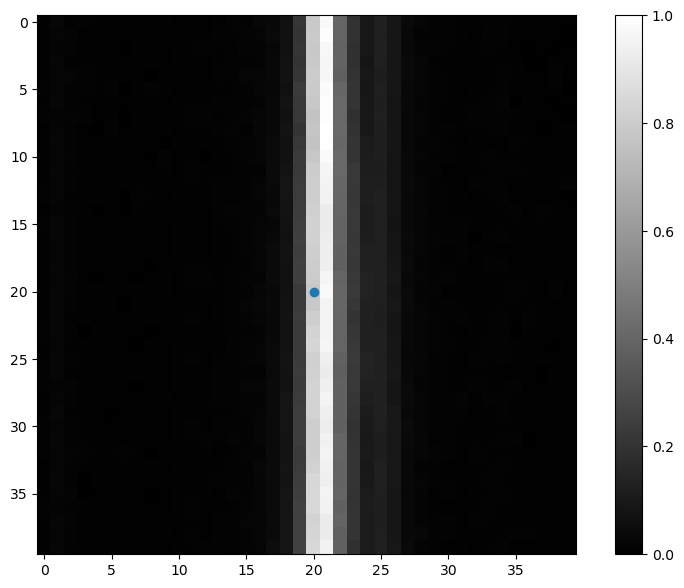

1


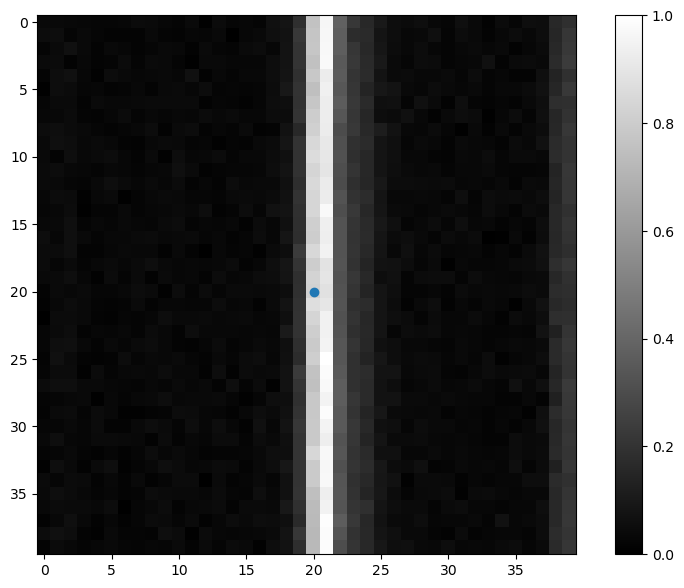

2


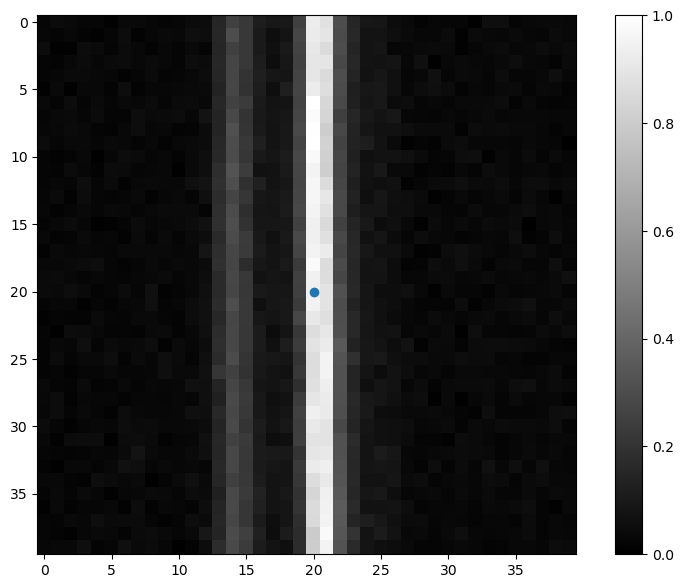

3


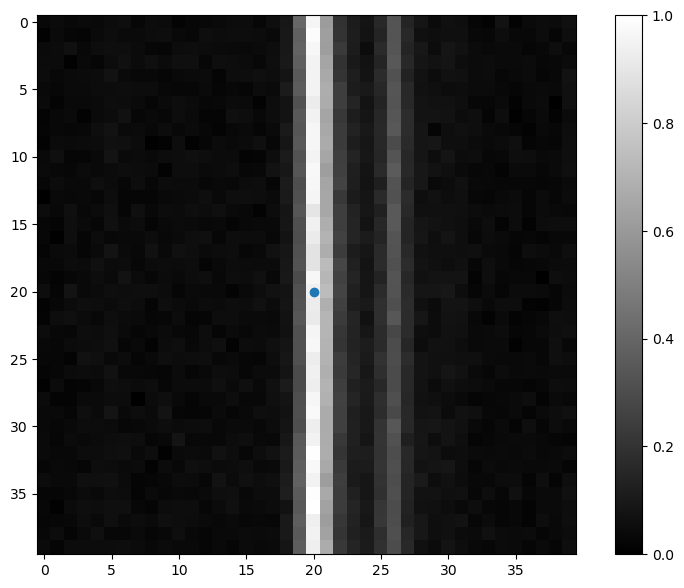

4


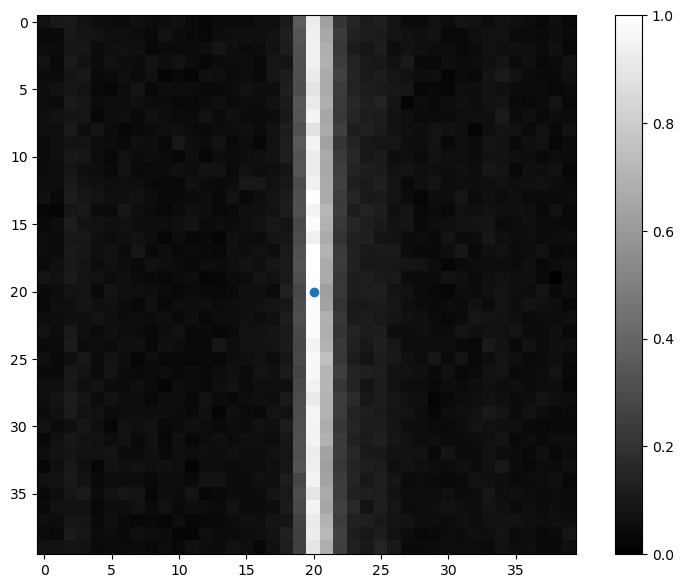

5


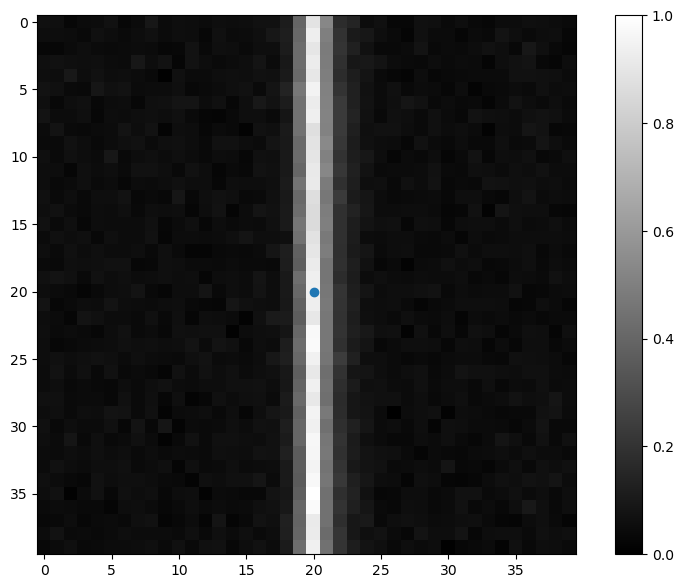

6


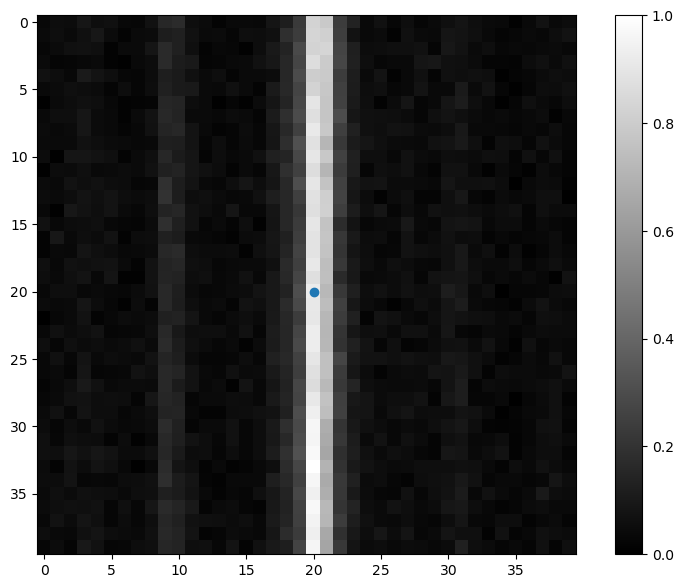

7


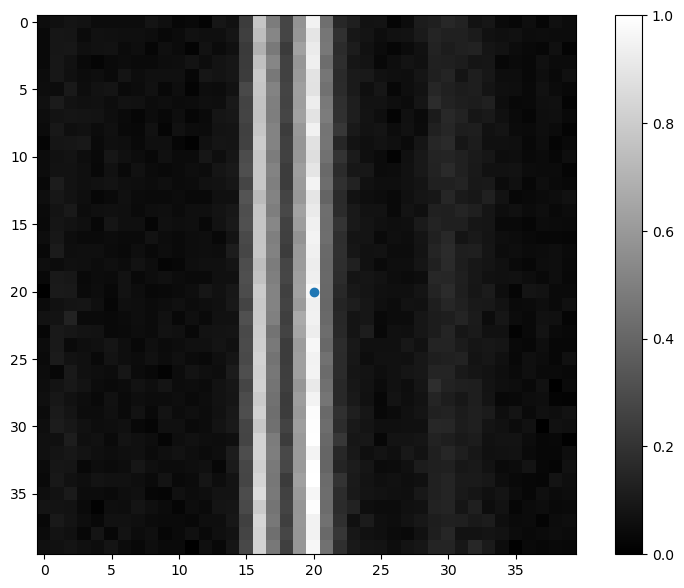

8


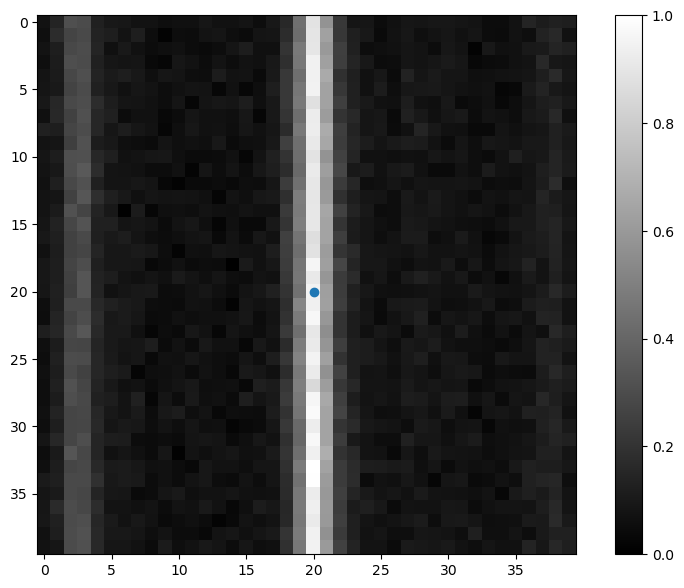

9


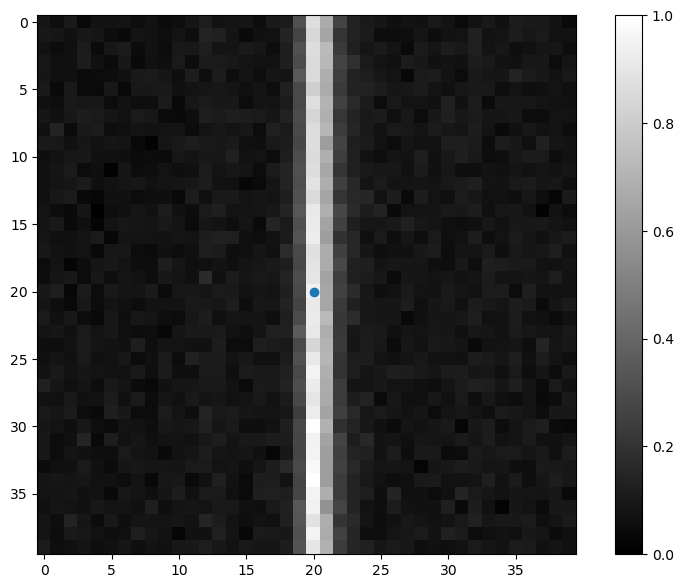

10


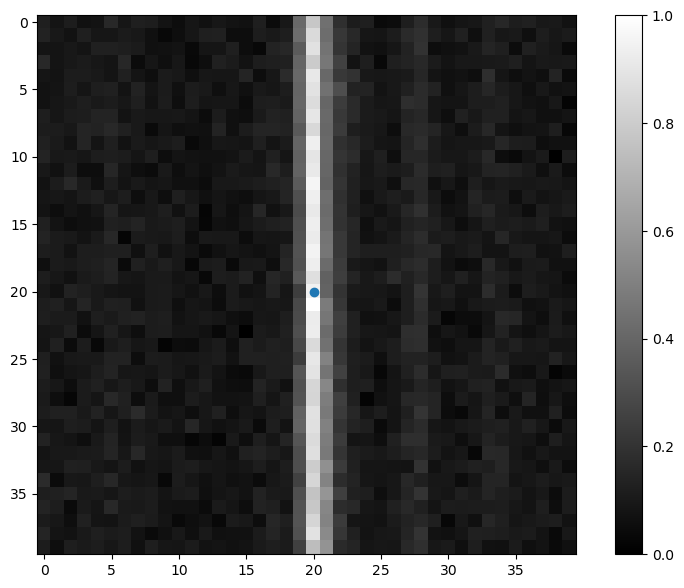

11


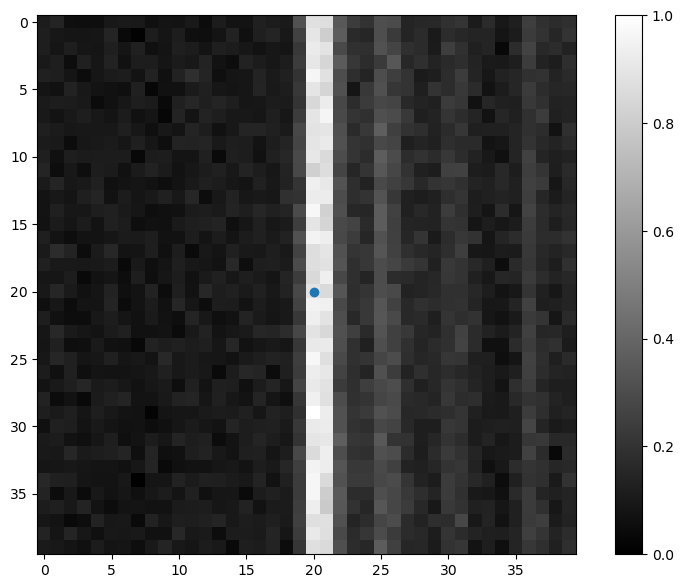

12


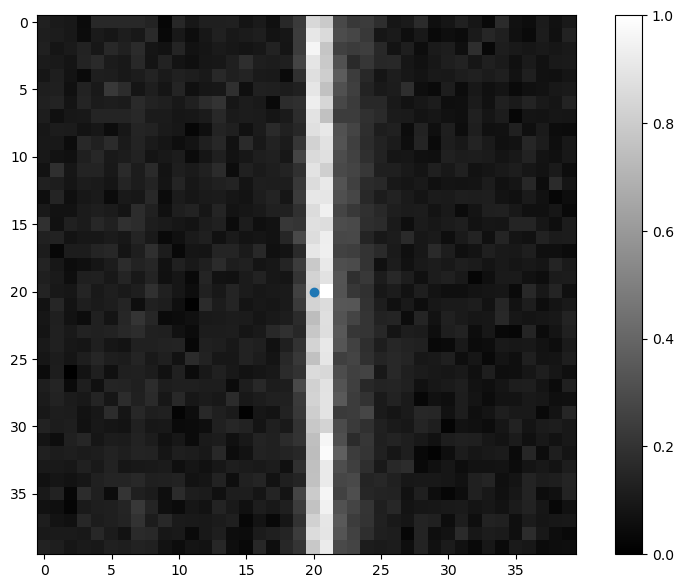

13


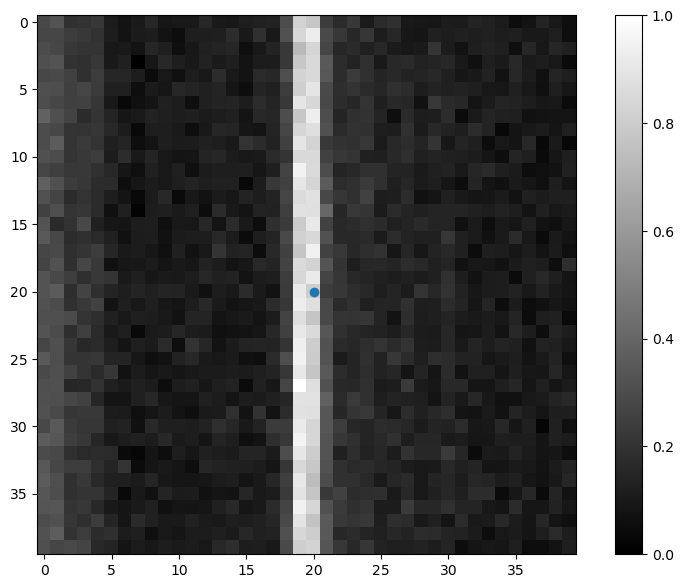

14


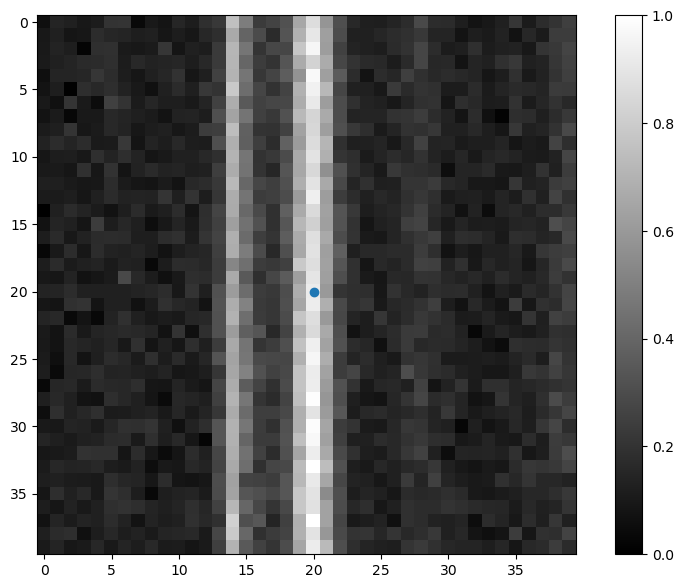

15


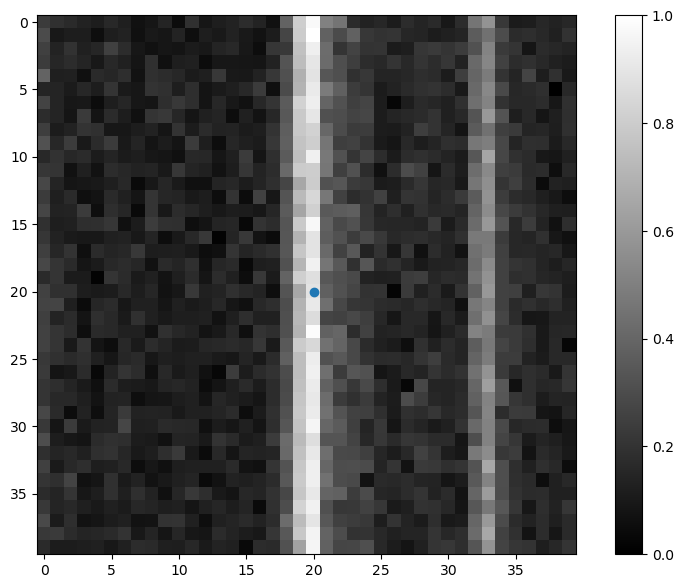

16


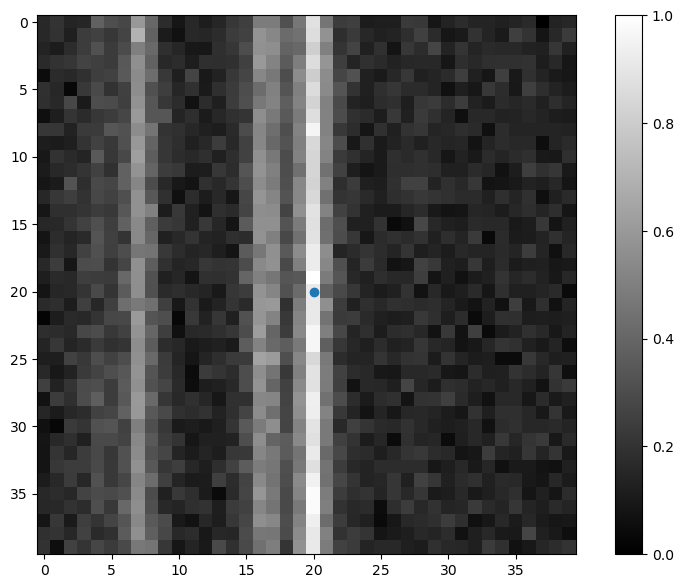

17


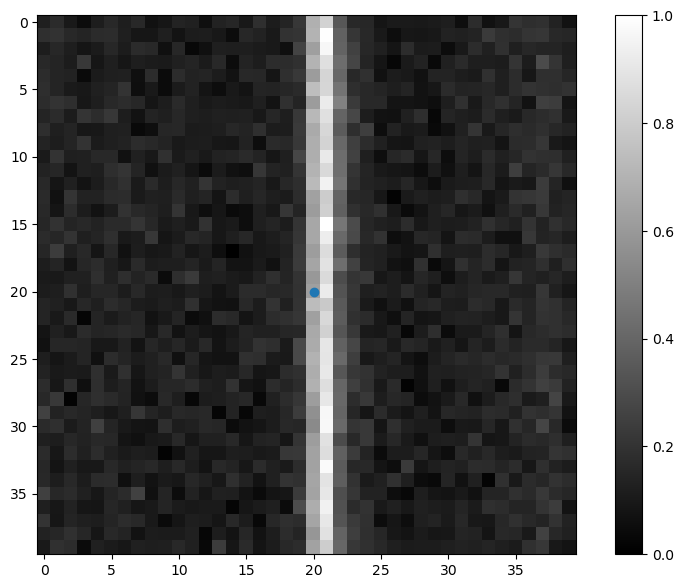

18


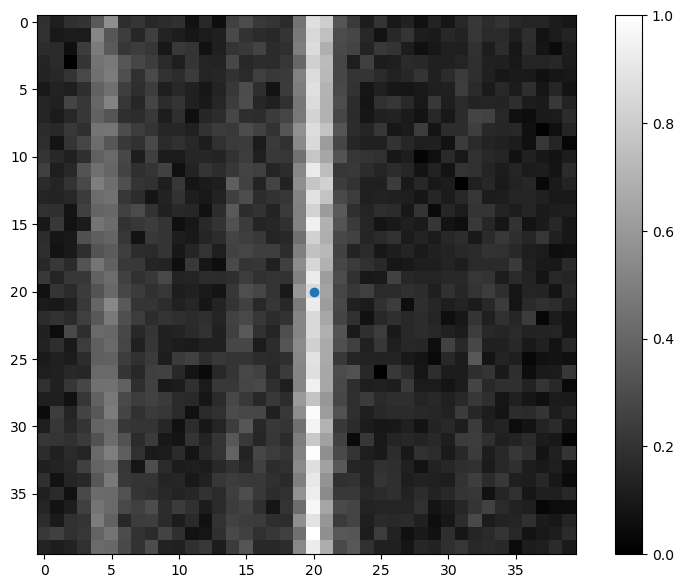

19


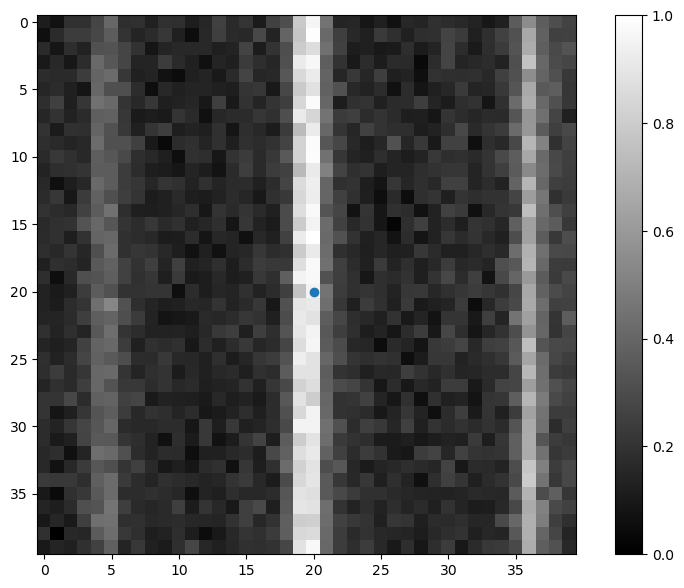

20


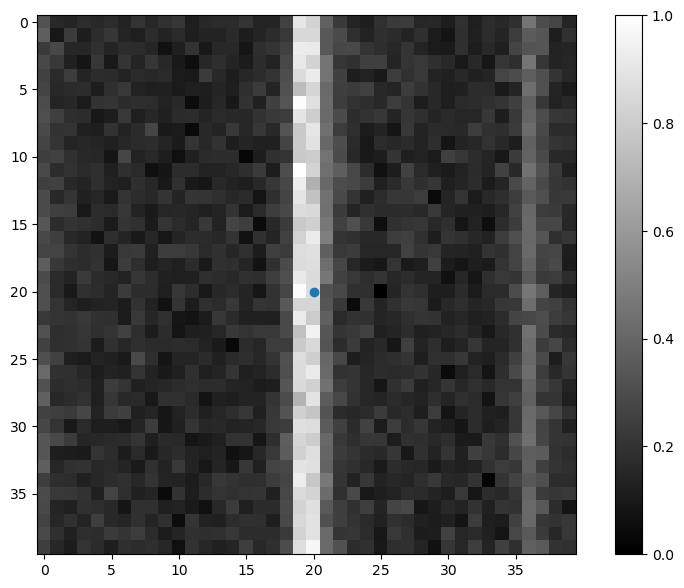

21


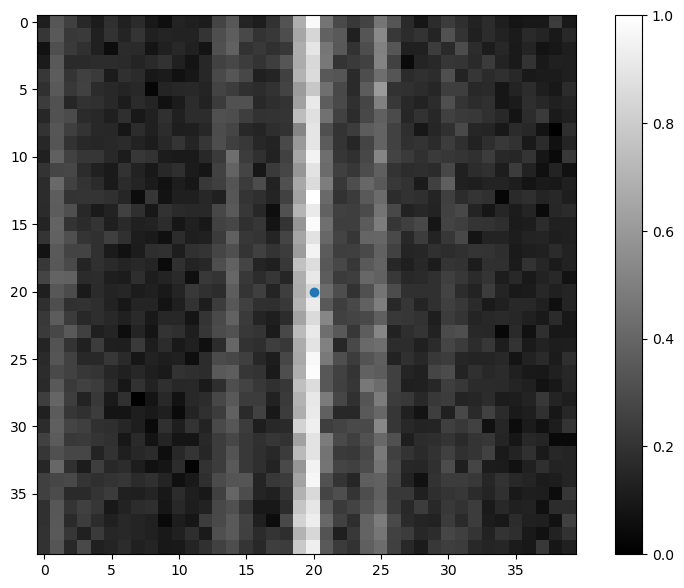

22


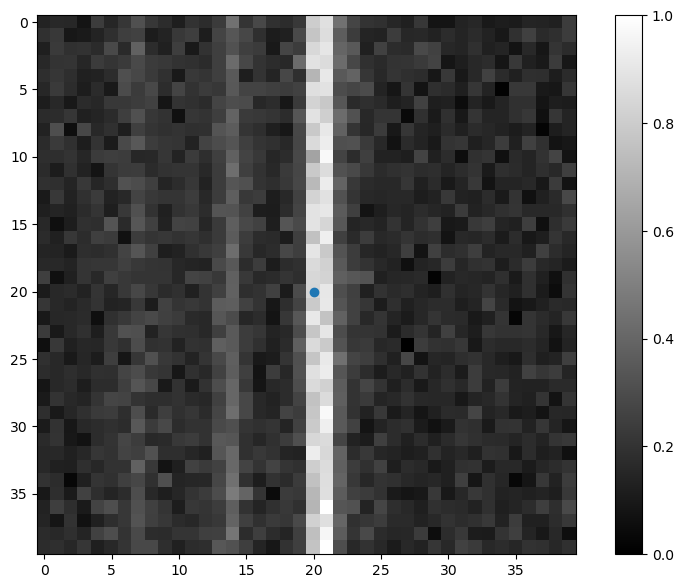

23


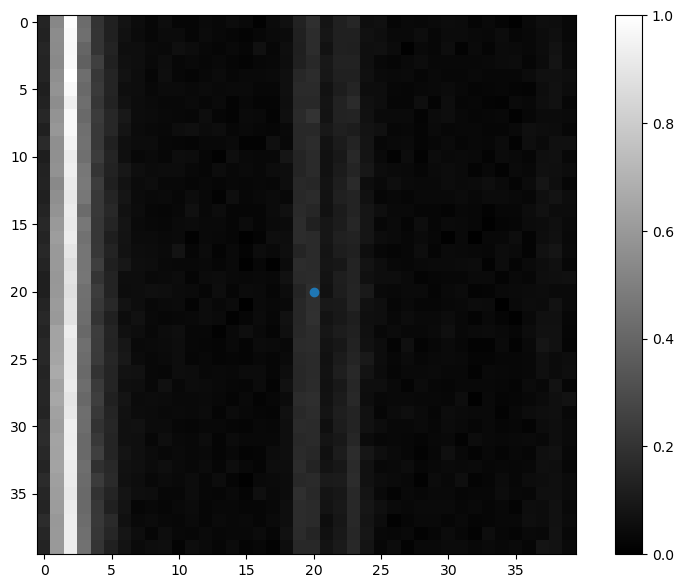

24


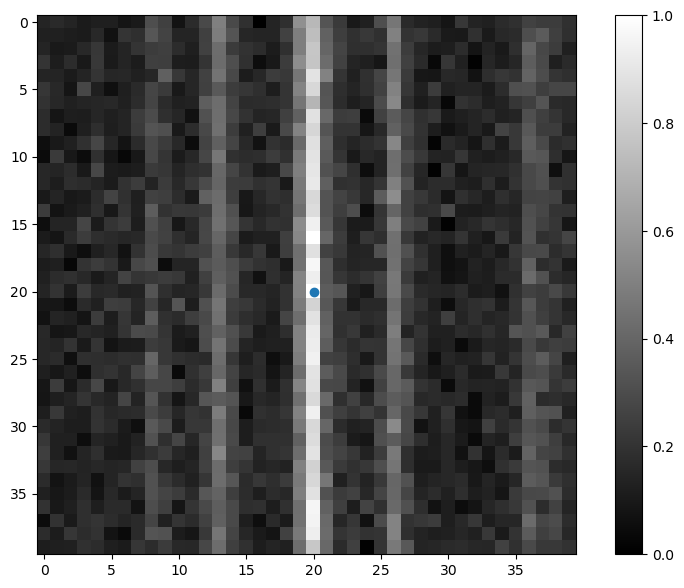

25


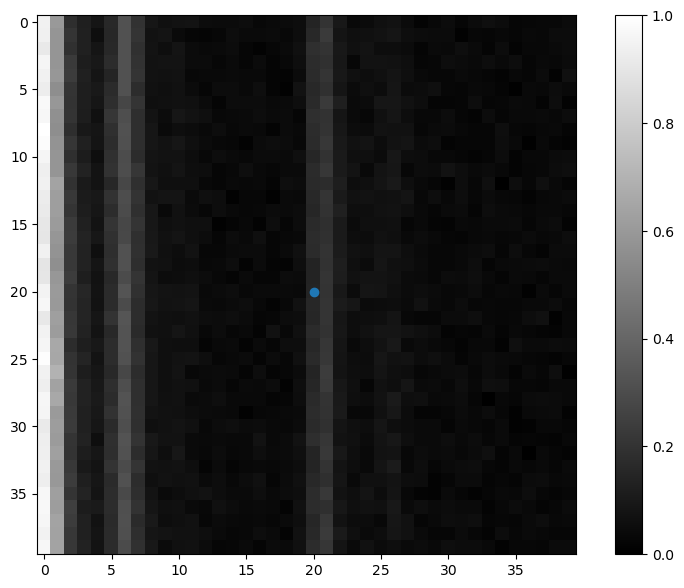

26


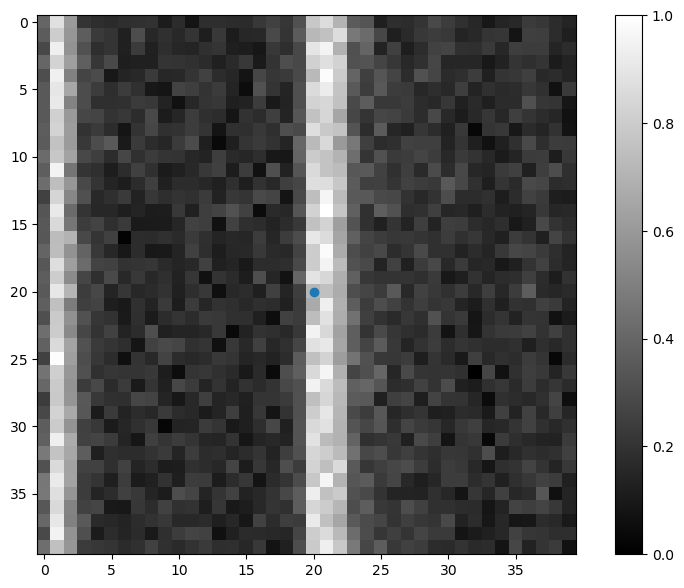

27


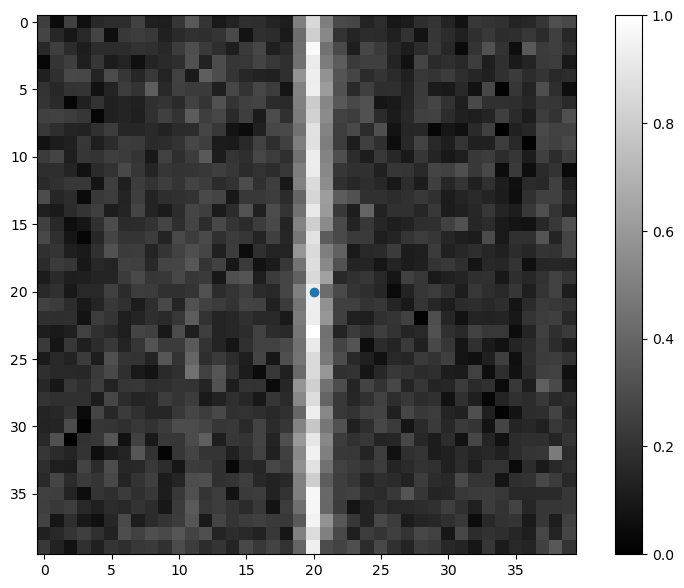

28


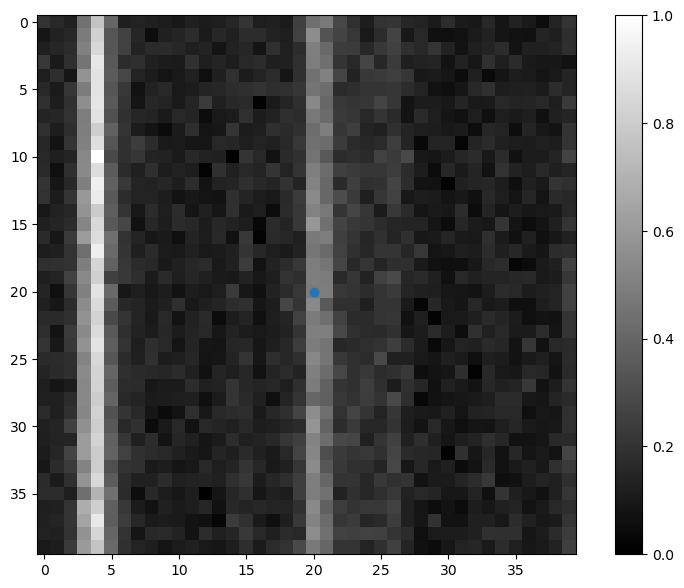

29


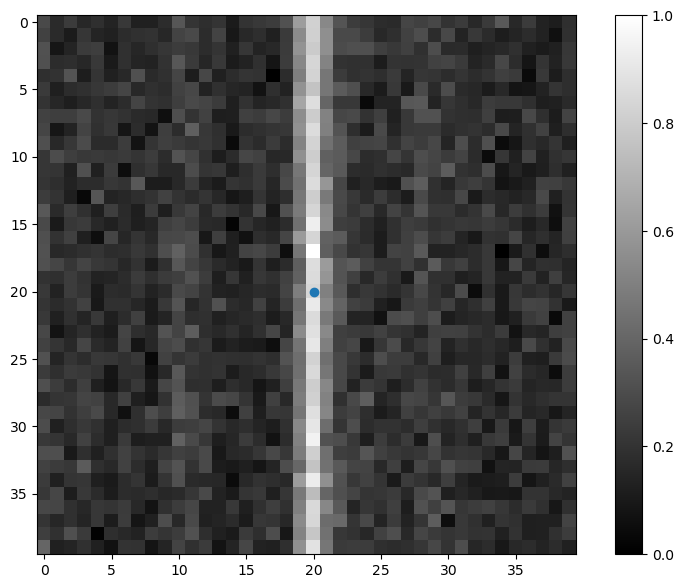

30


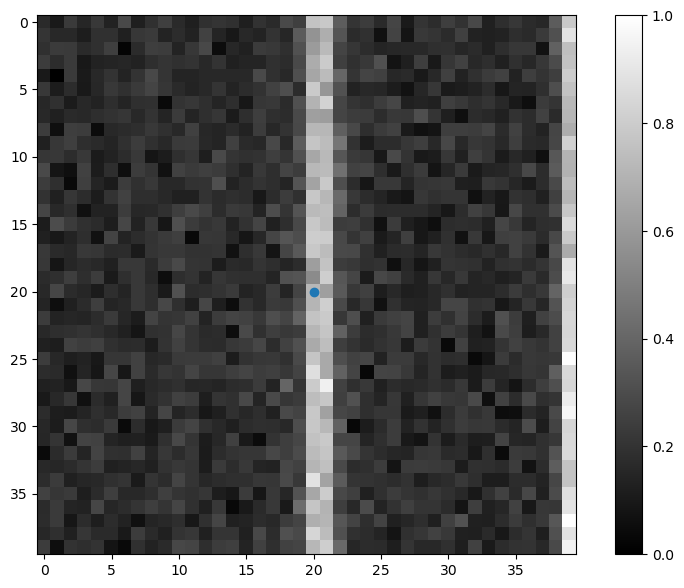

31


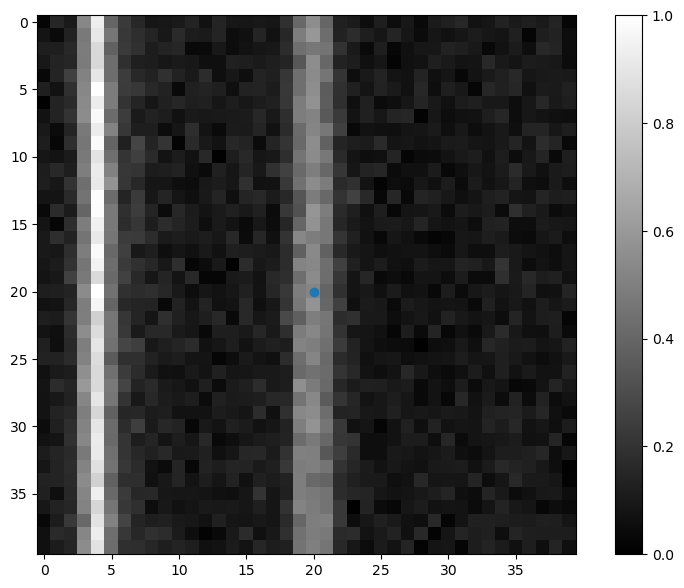

32


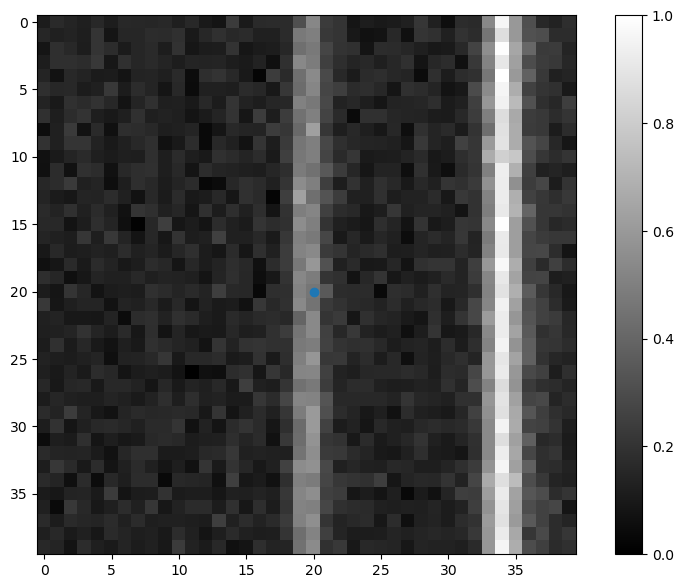

33


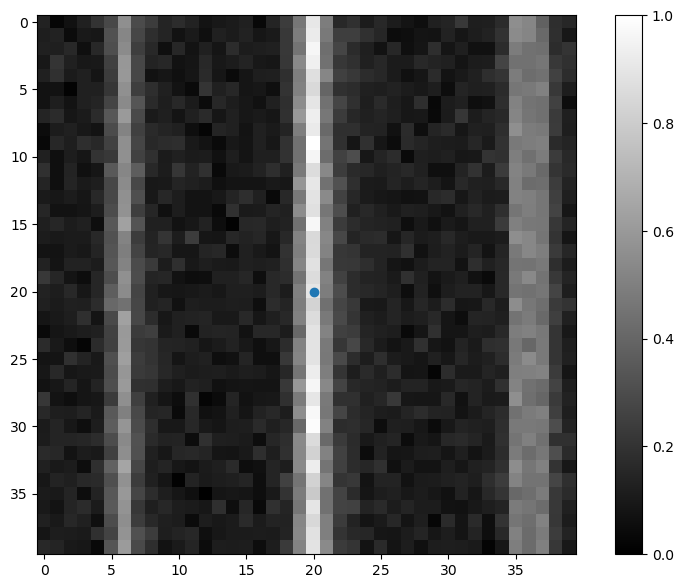

34


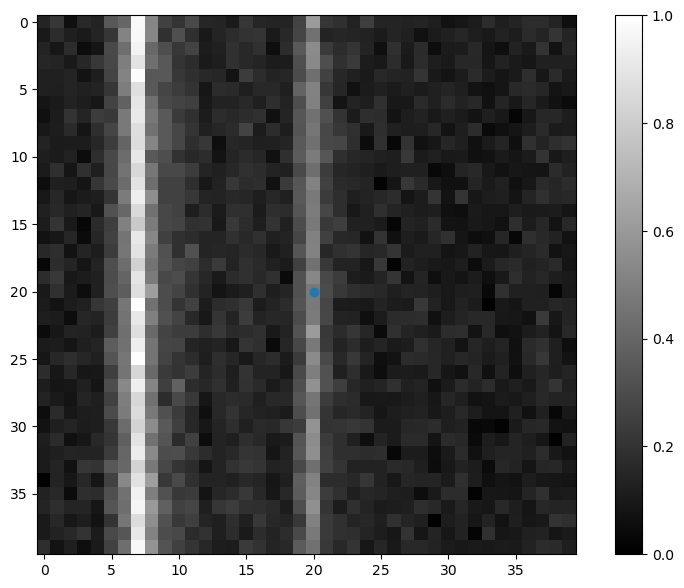

35


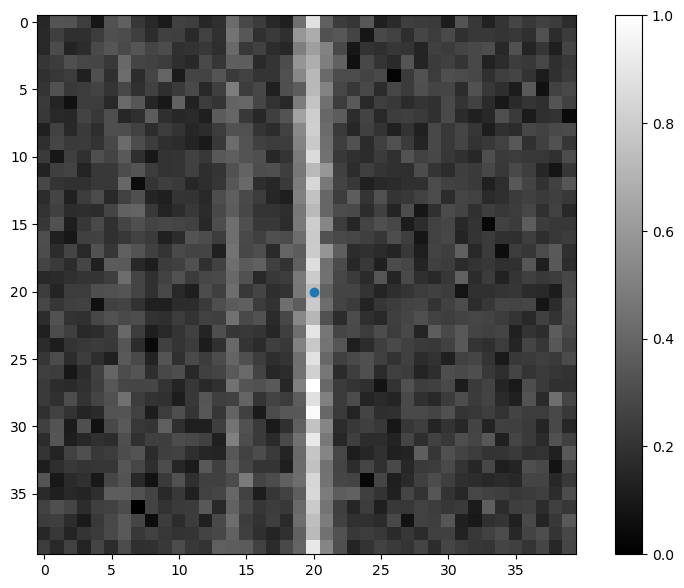

In [59]:

# plt.imshow(np.sqrt(np.load(image_file)))
with fits.open(xy_file) as hdul:
    if len(hdul[1].data["x"])>15:
        maxnum = len(hdul[1].data["x"])
    else:
        maxnum = 15
    for i in range(maxnum):
        print(i)
        x = int(hdul[1].data["x"][i])
        y = int(hdul[1].data["y"][i])
        plt.imshow(np.sqrt(np.load(image_file)[y-20:y+20, x-20:x+20]))
        plt.scatter(20,20)
        # plt.scatter(hdul[1].data["x"], hdul[1].data["y"])[y-5:y+5, x-5:x+5]
        # plt.xlim(x-5, x+5)
        # plt.ylim(y-5, y+5)
        # plt.relim()
# update ax.viewLim using the new dataLim
        # plt.autoscale(axis=2)
        plt.colorbar()
        plt.show()
        